In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import tqdm
import os
import glob
import cv2
import matplotlib.pyplot as plt


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).



### Construction sample weigths of mask

In [ ]:
mask_path = os.path.join("/content/drive/MyDrive/Proyecto RxTx/ChestRay/masks/")
mask1 = os.listdir(mask_path)

print("Total máscaras:",len(mask1))


Total máscaras: 704


In [ ]:
## creación de los pesos:
def weigths(y_true):
    gray = y_true
    #gray = cv2.cvtColor(gray,cv2.COLOR_BGR2GRAY)

    kernel = np.ones((5,5),np.uint8)
    gradient = 255*(cv2.morphologyEx(gray, cv2.MORPH_GRADIENT, kernel)<100).astype('uint8')
    dist_transform = cv2.distanceTransform(gradient,cv2.DIST_L1,3)
    # dist_transform = dist_transform.max()-dist_transform
    # dist_transform *= 0.9/dist_transform.max()
    # dist_transform += 0.1
    #dist_transform /= dist_transform.max()
    #w = np.exp(-3*dist_transform.astype('float32'))
    w = 1.0*(dist_transform<5)
    return dist_transform



(-0.5, 223.5, 223.5, -0.5)

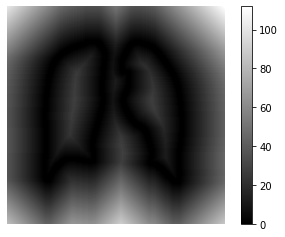

In [ ]:
i=0
im = cv2.resize(cv2.imread(os.path.join(mask_path+mask1[i])),(224,224))[:,:,1] #/255
w = weigths(im)
plt.imshow(w,cmap='gray')
plt.colorbar()
plt.axis('off')

In [ ]:
mascara = []
mask_array = []
weigths_m = []
for i in range(0,704):
    mascara.append(mask_path+mask1[i])
    im = cv2.resize(cv2.imread(os.path.join(mask_path+mask1[i])),(224,224))[:,:,1] #/255
    mask_array.append(im)

    weigths_m.append(weigths(im))

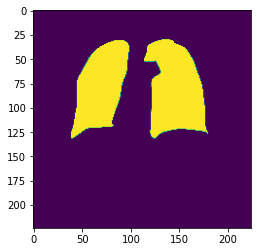

In [ ]:
plt.imshow(mask_array[16])

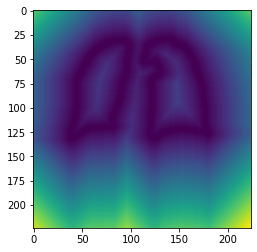

In [ ]:
plt.imshow(weigths_m[16])

In [ ]:
np.array(weigths_m).shape

(704, 224, 224)

In [ ]:
weigths = []
for i in range(0,704):
  cv2.imwrite(f"/content/drive/MyDrive/Proyecto RxTx/segmentation/weigths_lineal/"+mask1[i],weigths_m[i])
  weigths.append(f"/content/drive/MyDrive/Proyecto RxTx/segmentation/weigths_lineal/"+mask1[i])

## Dataloader

In [ ]:
meta = pd.read_csv("/content/drive/MyDrive/Proyecto RxTx/ChestRay/datase - datase.csv")
len(meta)

92028

In [ ]:
meta = meta[meta['w_segm'].isin([1.0])]
meta = meta.assign(weigths=weigths)
len(meta)

704

In [ ]:
meta.head()


,Unnamed: 0,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],...,Nodule,Mass,Hernia,No Finding,target_vector,Unnamed: 30,Unnamed: 31,w_label,w_segm,weigths
91324,112120,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1.0,/content/drive/MyDrive/Proyecto RxTx/segmentat...
91325,112121,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1.0,/content/drive/MyDrive/Proyecto RxTx/segmentat...
91326,112122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1.0,/content/drive/MyDrive/Proyecto RxTx/segmentat...
91327,112123,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1.0,/content/drive/MyDrive/Proyecto RxTx/segmentat...
91328,112124,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,1.0,/content/drive/MyDrive/Proyecto RxTx/segmentat...


In [ ]:
ampa = cv2.imread(meta['full_path'].iloc[0])
ampa.shape

(2933, 3000, 3)

In [ ]:
#meta = meta[meta['View Position'] == 'AP']
len(meta)

704

In [ ]:
meta_labels = np.array(meta[['Consolidation',	'Infiltration'	,'Pneumothorax',	'Edema'	,'Emphysema'	,'Fibrosis'	,'Effusion'	,'Pneumonia',	'Atelectasis',	'Pleural_Thickening',	'Cardiomegaly',	'Nodule'	,'Mass',	'Hernia']])
meta_labels[98].shape

(14,)

In [ ]:
meta_labels

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [ ]:
meta['full_path'][92028-704]

'/content/drive/MyDrive/Proyecto RxTx/ChestRay/CXR_png/CHNCXR_0005_0.png'

In [ ]:
data_ds = tf.data.Dataset.from_tensor_slices((meta['full_path'],meta_labels, meta['mask'],np.array(meta['w_label']),np.array(meta['w_segm']),meta['weigths']))

In [ ]:
#funciones para  lectura
def decode_img(img):
  img = tf.image.decode_png(img, channels=3) #formato de la img de entrada es bmp
  img = tf.image.convert_image_dtype(img, tf.float32) #llevamos la imagen a float
  return tf.image.resize(img, (224,224)) #resize a 224,224

def decode_img_mask(img):
  img = tf.image.decode_png(img, channels=3) #formato de la img de entrada es png
  img = tf.image.convert_image_dtype(img, tf.float32)
  return tf.image.resize(img, (224,224))

def decode_img_weigth(img):
  img = tf.image.decode_png(img, channels=3) #formato de la img de entrada es png
  img = tf.image.convert_image_dtype(img, tf.float32)
  return tf.image.resize(img, (224,224))

def process_path(filepath, label, mask,wl,ws,weigths_pesos):
  img = tf.io.read_file(filepath)
  img1 = decode_img(img)

  mask = tf.io.read_file(mask)
  mask = decode_img_mask(mask)

  w    =  img = tf.io.read_file(weigths_pesos)
  w    = decode_img_weigth(w)
  return img1, label, mask,wl,ws, w

In [ ]:
data_im = data_ds.map(process_path, num_parallel_calls=tf.data.experimental.AUTOTUNE)
    # .apply(tf.data.experimental.ignore_errors()).cache('/content/train_cache')

In [ ]:
data_im

<ParallelMapDataset element_spec=(TensorSpec(shape=(224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(14,), dtype=tf.float64, name=None), TensorSpec(shape=(224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.float64, name=None), TensorSpec(shape=(), dtype=tf.float64, name=None), TensorSpec(shape=(224, 224, 3), dtype=tf.float32, name=None))>

### Create TFRecord

In [ ]:
# TR_SHARDS = 10
TR_SHARDS = 1
GCS_OUTPUT = '/content/drive/MyDrive/Proyecto RxTx/segmentation/TF_RECORDS_REG/'

In [ ]:
# import math
# data_size = len(meta)
# shard_size = math.ceil(1.0 * data_size/ TR_SHARDS)

In [ ]:
# shard_size = math.ceil(shard_size/33)
# shard_size

In [ ]:
def recompress_image(image, label, mask,wl,ws,w):
  image = image * 255.0
  image = tf.cast(image, tf.uint8)
  image = tf.image.encode_jpeg(image, optimize_size=True, chroma_downsampling=False)
  mask = mask * 255.0
  mask = tf.cast(mask, tf.uint8)
  mask = tf.image.encode_jpeg(mask, optimize_size=True, chroma_downsampling=False)
  w = w * 255.0
  w = tf.cast(w, tf.uint8)
  w = tf.image.encode_jpeg(w, optimize_size=True, chroma_downsampling=False)
  return image, label, mask,wl,ws, w

In [ ]:
data_imc = data_im.map(recompress_image, num_parallel_calls=tf.data.experimental.AUTOTUNE)
#data_imc = data_imc.batch(shard_size).prefetch(tf.data.experimental.AUTOTUNE)
data_imc = data_imc.batch(1).prefetch(tf.data.experimental.AUTOTUNE)


In [ ]:
data_imc

<PrefetchDataset element_spec=(TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None, 14), dtype=tf.float64, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None), TensorSpec(shape=(None,), dtype=tf.float64, name=None), TensorSpec(shape=(None,), dtype=tf.float64, name=None), TensorSpec(shape=(None,), dtype=tf.string, name=None))>

In [ ]:
# Three types of data can be stored in TFRecords: bytestrings, integers and floats
# They are always stored as lists, a single data element will be a list of size 1

def _bytestring_feature(list_of_bytestrings):
  return tf.train.Feature(bytes_list=tf.train.BytesList(value=list_of_bytestrings))

def _int_feature(list_of_ints): # int64
  return tf.train.Feature(int64_list=tf.train.Int64List(value=list_of_ints))

def _float_feature(list_of_floats): # float32
  return tf.train.Feature(float_list=tf.train.FloatList(value=list_of_floats))

def _float_array_feature(value):
  return tf.train.Feature(float_list=tf.train.FloatList(value=value))

def to_tfrecord(tfrec_filewriter, img, label, mask,wl,ws,w):

  feature = {
      "image": _bytestring_feature([img]),
      "label":     _float_feature(label),
      "mask": _bytestring_feature([mask]),
      "w_label":     _int_feature(wl),
      "w_segm":     _int_feature(ws),
      "weigths":    _bytestring_feature([w]),
    }
  return tf.train.Example(features=tf.train.Features(feature=feature))


In [ ]:
TR_SHARDS = 1

In [ ]:
  print("Writing TFRecords")

for shard, (image, label, mask,wl,ws,weigths) in tqdm.tqdm(enumerate(data_imc)):
  # batch size used as shard size here
   shard_size = image.numpy().shape[0]
  # good practice to have the number of records in the filename
   filename = GCS_OUTPUT + "{:02d}.tfrec".format(shard, shard_size)
   if os.path.exists(filename):
     continue
   with tf.io.TFRecordWriter(filename) as out_file:
    for i in tqdm.tqdm(range(shard_size)):
      example = to_tfrecord(out_file,
                            image.numpy()[i],
                            label.numpy()[i],
                            mask.numpy()[i], #TAREA DE JUAN CAMILO
                            wl,
                            ws,
                            weigths.numpy()[i]#TAREA DE JUAN CAMILO
                            #mask.numpy()[i]
                            )
      out_file.write(example.SerializeToString())
    print("Wrote file {} containing {} records".format(filename, shard_size))

Writing TFRecords


0it [00:00, ?it/s]
100%|██████████| 1/1 [00:00<00:00, 109.14it/s]
1it [00:00,  1.75it/s]

Wrote file /content/drive/MyDrive/Proyecto RxTx/segmentation/TF_RECORDS_REG/00.tfrec containing 1 records



100%|██████████| 1/1 [00:00<00:00, 300.04it/s]


Wrote file /content/drive/MyDrive/Proyecto RxTx/segmentation/TF_RECORDS_REG/01.tfrec containing 1 records



100%|██████████| 1/1 [00:00<00:00, 337.65it/s]
3it [00:01,  1.61it/s]

... (1,399 outputs left out)


100%|██████████| 1/1 [00:00<00:00, 323.43it/s]


Wrote file /content/drive/MyDrive/Proyecto RxTx/segmentation/TF_RECORDS_REG/702.tfrec containing 1 records



100%|██████████| 1/1 [00:00<00:00, 139.03it/s]
704it [05:28,  2.14it/s]


Wrote file /content/drive/MyDrive/Proyecto RxTx/segmentation/TF_RECORDS_REG/703.tfrec containing 1 records


In [ ]:
def read_tfrecord(example):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),  # tf.string = bytestring (not text string)
        "label": tf.io.VarLenFeature(tf.float32),
        "mask": tf.io.FixedLenFeature([], tf.string),        # a certain number of floats0
        # "size":  tf.io.FixedLenFeature([2], tf.int64),  # two integers
    }
    # decode the TFRecord
    example = tf.io.parse_single_example(example, features)

    # FixedLenFeature fields are now ready to use: exmple['size']
    # VarLenFeature fields require additional sparse_to_dense decoding

    image = tf.image.decode_jpeg(example['image'], channels=3)
    label  = tf.reshape(tf.sparse.to_dense(example['label']), [-1, 14])
    height = 224,#example['size'][0]
    width  = 224,#example['size'][1]
    image = tf.reshape(image, [224,224,3])
    return image, label

In [ ]:
# read from TFRecords. For optimal performance, read from multiple
# TFRecord files at once and set the option experimental_deterministic = False
# to allow order-altering optimizations.

option_no_order = tf.data.Options()
option_no_order.experimental_deterministic = False

filenames = tf.io.gfile.glob(GCS_OUTPUT + "*.tfrec")
train_dsr = tf.data.TFRecordDataset(filenames, num_parallel_reads=tf.data.experimental.AUTOTUNE)
train_dsr = train_dsr.with_options(option_no_order)
train_dsr = train_dsr.map(read_tfrecord, num_parallel_calls=tf.data.experimental.AUTOTUNE)
train_dsr = train_dsr.shuffle(300)